<a href="https://colab.research.google.com/github/vyakhyaagoyal/DL_Lab_V/blob/main/Vyakhya_Goyal_Lab_07_Part_II_Closed_Set_Face_Identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab-07 — Introduction to PyTorch and CNN-Based Image Classification  
## Part II: Guided CNN-Based Closed-Set Face Identification

**Default public dataset:** AT&T/ORL Database of Faces (Olivetti faces), 40 enrolled identities × 10 images each.

### Objective
Develop and evaluate a PyTorch CNN for **closed-set face identification**, including:
- dataset inspection,
- class-wise splitting,
- deterministic preprocessing and training augmentation,
- CNN architecture design,
- training/validation,
- learning curves,
- confusion matrix,
- precision/recall/F1,
- misclassification analysis,
- fresh-image inference,
- closed-set limitation analysis.

> This is a **multi-class classification laboratory exercise**, not a production biometric system.


## Ethical requirement

If you use the optional custom dataset:
- collect images only from participants who have **explicitly consented** to classroom use,
- do not scrape personal images from social media or unrelated sources,
- keep the dataset only as long as needed for the laboratory activity,
- do not use the notebook for covert identification.

For a reproducible classroom run, use the public ORL/Olivetti dataset.


## 1. Setup and supporting files

Upload:
- `testCases_lab07_part2.py`
- `public_tests_lab07_part2.py`
- `lab07_part2_utils.py`

The notebook uses the standard CNN notation \(H,W,C,F,P,S,K\), while PyTorch tensors use `[N,C,H,W]`.


In [1]:
import os, random, copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.datasets import fetch_olivetti_faces
from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_recall_fscore_support, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device :", device)


PyTorch: 2.11.0+cpu
Device : cpu


In [2]:
from public_tests_lab07_part2 import (
    test_face_cnn, test_stratified_split,
    test_predict_probabilities, run_all_tests
)
from lab07_part2_utils import (
    count_trainable_parameters, plot_learning_curves,
    show_face_grid, show_misclassified
)
print("Supporting files imported.")


Supporting files imported.


# 2. Load and inspect the AT&T/ORL (Olivetti) face dataset

`fetch_olivetti_faces()` provides:
- 400 grayscale images,
- spatial size \(64\times64\),
- 40 subjects,
- 10 images per subject.

The theoretical input volume is:

\[
64\times64\times1.
\]


In [3]:
faces = fetch_olivetti_faces(shuffle=False, download_if_missing=True)
X_faces = faces.images.astype(np.float32)   # [400,64,64], values in [0,1]
y_faces = faces.target.astype(np.int64)     # [400]

print("Images :", X_faces.shape)
print("Labels :", y_faces.shape)
print("Classes:", len(np.unique(y_faces)))
print("Pixel range:", X_faces.min(), "to", X_faces.max())

counts = np.bincount(y_faces)
print("Images per class — min/max:", counts.min(), counts.max())


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Images : (400, 64, 64)
Labels : (400,)
Classes: 40
Pixel range: 0.0 to 1.0
Images per class — min/max: 10 10


### 2.1 Display at least two examples from several identities


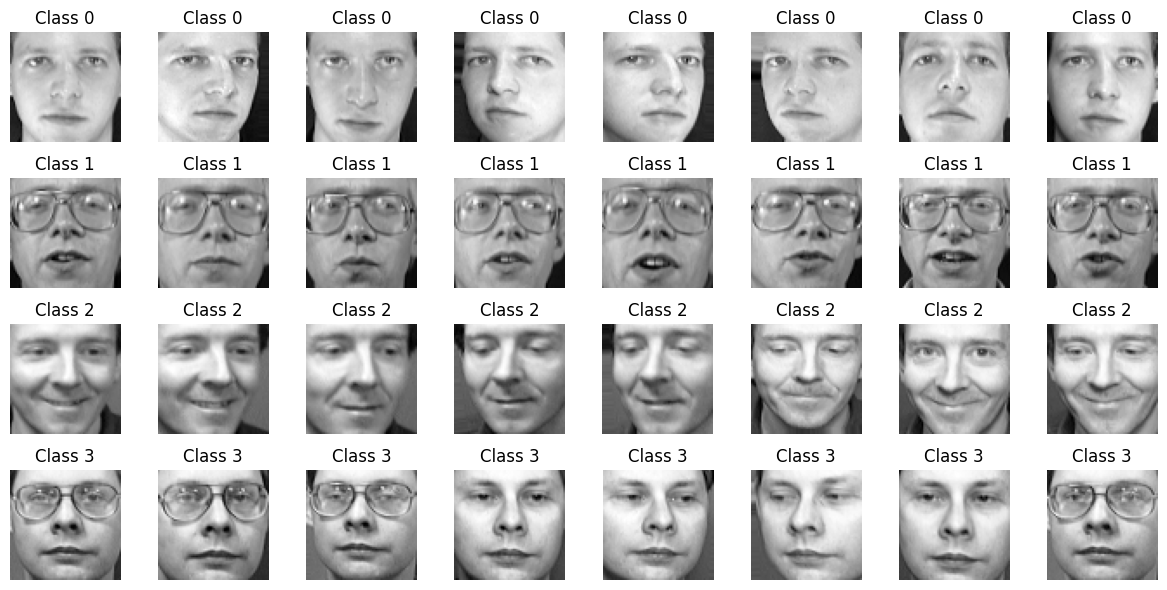

In [4]:
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for subject in range(4):
    idx = np.where(y_faces == subject)[0][:8]
    for j, k in enumerate(idx):
        axes[subject, j].imshow(X_faces[k], cmap="gray")
        axes[subject, j].set_title(f"Class {subject}")
        axes[subject, j].axis("off")
plt.tight_layout()
plt.show()


### Student observation
Record:
- \(N_{\mathrm{class}}\),
- images per identity,
- \(H_{\mathrm{in}},W_{\mathrm{in}},C_{\mathrm{in}}\),
- visible variation in pose/expression/illumination.

For ORL, each identity has only 10 samples, so the split must be **class-wise**.


## 3. Deterministic class-wise train/validation/test split — student-completion function


In [7]:
def stratified_indices(y, train_per_class=6, val_per_class=2, seed=42):
    """
    Create mutually exclusive class-wise indices.

    For ORL default:
      6 training + 2 validation + 2 test = 10 images/class.
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y)

    train_idx, val_idx, test_idx = [], [], []

    # YOUR CODE STARTS HERE
    classes = np.unique(y)
    for c in classes:
        class_indices = np.where(y == c)[0].copy()
        rng.shuffle(class_indices)

        train_idx.extend(class_indices[:train_per_class])
        val_idx.extend(class_indices[train_per_class:train_per_class + val_per_class])
        test_idx.extend(class_indices[train_per_class + val_per_class:])
    # YOUR CODE ENDS HERE

    return (
        np.asarray(train_idx, dtype=int),
        np.asarray(val_idx, dtype=int),
        np.asarray(test_idx, dtype=int)
    )

train_idx, val_idx, test_idx = stratified_indices(y_faces, 6, 2, seed=SEED)
print(len(train_idx), len(val_idx), len(test_idx))

240 80 80


In [8]:
test_stratified_split(stratified_indices)


✓ stratified_indices: passed


In [9]:
# Verify no overlap
assert set(train_idx).isdisjoint(set(val_idx))
assert set(train_idx).isdisjoint(set(test_idx))
assert set(val_idx).isdisjoint(set(test_idx))

print("Training   :", len(train_idx))
print("Validation :", len(val_idx))
print("Test       :", len(test_idx))
print("Per-class train counts:", np.unique(np.bincount(y_faces[train_idx]), return_counts=True))


Training   : 240
Validation : 80
Test       : 80
Per-class train counts: (array([6]), array([40]))


# 4. Dataset class and transforms

Training augmentation should be **controlled**. Validation/test preprocessing must be deterministic.

For grayscale ORL images we normalize approximately around the \([0,1]\) range using:

\[
x_{\mathrm{norm}}=\frac{x-0.5}{0.5}.
\]

That maps roughly to \([-1,1]\).


In [10]:
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

class FaceArrayDataset(Dataset):
    def __init__(self, images, labels, indices, transform=None):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        image = self.images[idx]
        label = int(self.labels[idx])

        if self.transform is not None:
            image = self.transform(image)
        else:
            image = torch.tensor(image[None, ...], dtype=torch.float32)

        return image, label

train_ds = FaceArrayDataset(X_faces, y_faces, train_idx, train_transform)
val_ds   = FaceArrayDataset(X_faces, y_faces, val_idx, eval_transform)
test_ds  = FaceArrayDataset(X_faces, y_faces, test_idx, eval_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("Mini-batch:", xb.shape, yb.shape)


Mini-batch: torch.Size([32, 1, 64, 64]) torch.Size([32])


### Optional custom consent-based class-folder dataset

If the instructor permits a custom dataset, organize it as:

```text
faces/
    person_01/
    person_02/
    ...
```

A robust custom-data workflow should create **separate train/val/test file lists or folders** before applying `ImageFolder`. Do not randomly augment validation/test samples.

The default ORL workflow above is sufficient for completing this lab.


# 5. Design the Face CNN

Architecture:

\[
64\times64\times1
\rightarrow
\text{Conv}(K=16)
\rightarrow \text{Pool}
\rightarrow
\text{Conv}(K=32)
\rightarrow \text{Pool}
\rightarrow
\text{Conv}(K=64)
\rightarrow \text{Pool}
\rightarrow
\text{Flatten}
\rightarrow128
\rightarrow\text{Dropout}
\rightarrow N_{\mathrm{class}}.
\]

Before executing the model, calculate:

| Layer | Parameters | Output \(H\times W\times C\) |
|---|---|---|
| Input | — | \(64\times64\times1\) |
| Conv1 | \(F=3,P=1,S=1,K=16\) | ? |
| Pool1 | \(F_{\mathrm{pool}}=2,S_{\mathrm{pool}}=2\) | ? |
| Conv2 | \(F=3,P=1,S=1,K=32\) | ? |
| Pool2 | \(F_{\mathrm{pool}}=2,S_{\mathrm{pool}}=2\) | ? |
| Conv3 | \(F=3,P=1,S=1,K=64\) | ? |
| Pool3 | \(F_{\mathrm{pool}}=2,S_{\mathrm{pool}}=2\) | ? |
| Flatten | — | ? |
| Dense | — | 128 |
| Output | — | \(N_{\mathrm{class}}\) logits |


### 5.1 FaceCNN — guided student-completion cell


In [12]:
class FaceCNN(nn.Module):
    def __init__(self, n_classes, in_channels=1):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # YOUR CODE STARTS HERE
            # TODO: add Conv2d(32 -> 64, F=3, P=1), ReLU, MaxPool2d(2,2)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # YOUR CODE ENDS HERE
        )

        # Complete this after tracing 64 -> 32 -> 16 -> 8 spatially.
        # YOUR CODE STARTS HERE
        flatten_dim = 8 * 8 * 64
        # YOUR CODE ENDS HERE

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flatten_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(128, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

N_CLASSES = len(np.unique(y_faces))
face_model = FaceCNN(N_CLASSES, in_channels=1).to(device)
print(face_model)
print("Trainable parameters:", count_trainable_parameters(face_model))


FaceCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=40, bias=True)
  )
)
Trainable parameters: 552872


In [13]:
test_face_cnn(FaceCNN)


✓ FaceCNN: passed


### 5.2 Verify intermediate dimensions


In [14]:
with torch.no_grad():
    x = xb[:2].to(device)
    print("Input       :", tuple(x.shape))
    for layer in face_model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:12s}: {tuple(x.shape)}")


Input       : (2, 1, 64, 64)
Conv2d      : (2, 16, 64, 64)
ReLU        : (2, 16, 64, 64)
MaxPool2d   : (2, 16, 32, 32)
Conv2d      : (2, 32, 32, 32)
ReLU        : (2, 32, 32, 32)
MaxPool2d   : (2, 32, 16, 16)
Conv2d      : (2, 64, 16, 16)
ReLU        : (2, 64, 16, 16)
MaxPool2d   : (2, 64, 8, 8)


# 6. Loss, optimizer, training, and validation

Use:
- `nn.CrossEntropyLoss()`
- Adam with initial learning rate \(10^{-3}\)

The training code saves the parameter state with the best validation accuracy.


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(face_model.parameters(), lr=1e-3)

def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    n = 0

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * X_batch.size(0)
            total_correct += (logits.argmax(dim=1) == y_batch).sum().item()
            n += X_batch.size(0)

    return total_loss / n, total_correct / n


Epoch 01/25 | train loss 3.7045 | train acc 0.021 | val loss 3.6864 | val acc 0.025
Epoch 05/25 | train loss 3.3181 | train acc 0.104 | val loss 3.0641 | val acc 0.200
Epoch 10/25 | train loss 1.9872 | train acc 0.388 | val loss 1.5938 | val acc 0.537
Epoch 15/25 | train loss 1.0696 | train acc 0.662 | val loss 0.6746 | val acc 0.812
Epoch 20/25 | train loss 0.6217 | train acc 0.796 | val loss 0.3415 | val acc 0.925
Epoch 25/25 | train loss 0.4365 | train acc 0.858 | val loss 0.2392 | val acc 0.938
Best validation accuracy: 0.9375


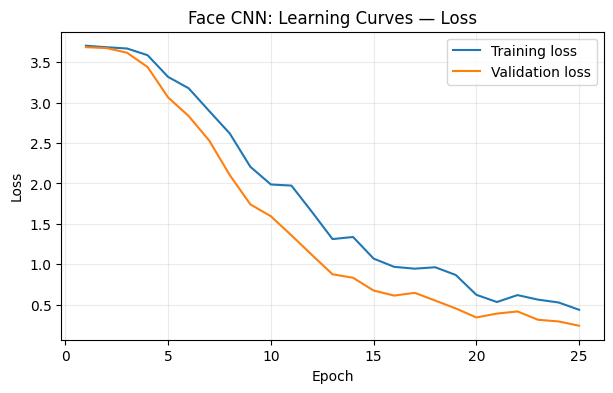

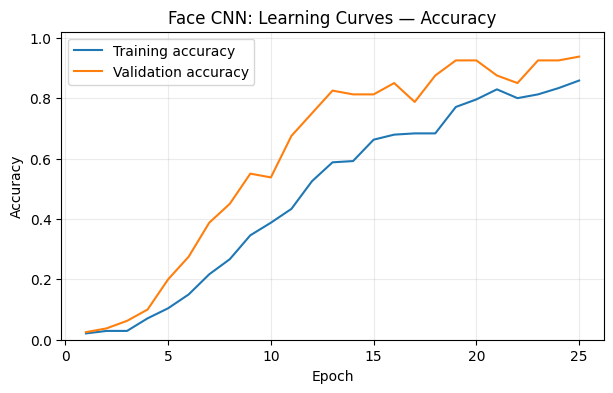

In [16]:
EPOCHS = 25
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_acc = -1.0
best_state = None

for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(face_model, train_loader, criterion, device, optimizer)
    va_loss, va_acc = run_epoch(face_model, val_loader, criterion, device, optimizer=None)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = copy.deepcopy(face_model.state_dict())

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
              f"train loss {tr_loss:.4f} | train acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} | val acc {va_acc:.3f}")

face_model.load_state_dict(best_state)
print("Best validation accuracy:", best_val_acc)
plot_learning_curves(history)


### Guided curve interpretation
Classify the observed behavior as one of:
- underfitting,
- reasonable generalization,
- overfitting.

Support your conclusion using the relative behavior of training/validation loss and accuracy.


# 7. Final test-set evaluation


In [17]:
@torch.no_grad()
def collect_face_predictions(model, loader, device):
    model.eval()
    images_out, y_true, y_pred, confs = [], [], [], []

    for X_batch, y_batch in loader:
        logits = model(X_batch.to(device))
        probs = torch.softmax(logits, dim=1)
        conf, pred = probs.max(dim=1)

        images_out.append(X_batch.cpu())
        y_true.append(y_batch.cpu())
        y_pred.append(pred.cpu())
        confs.append(conf.cpu())

    return (
        torch.cat(images_out),
        torch.cat(y_true).numpy(),
        torch.cat(y_pred).numpy(),
        torch.cat(confs).numpy()
    )

test_images, y_true, y_pred, confidences = collect_face_predictions(
    face_model, test_loader, device
)

test_acc = np.mean(y_true == y_pred)
print(f"Test accuracy: {test_acc:.4f}")


Test accuracy: 0.9625


### 7.1 Confusion matrix


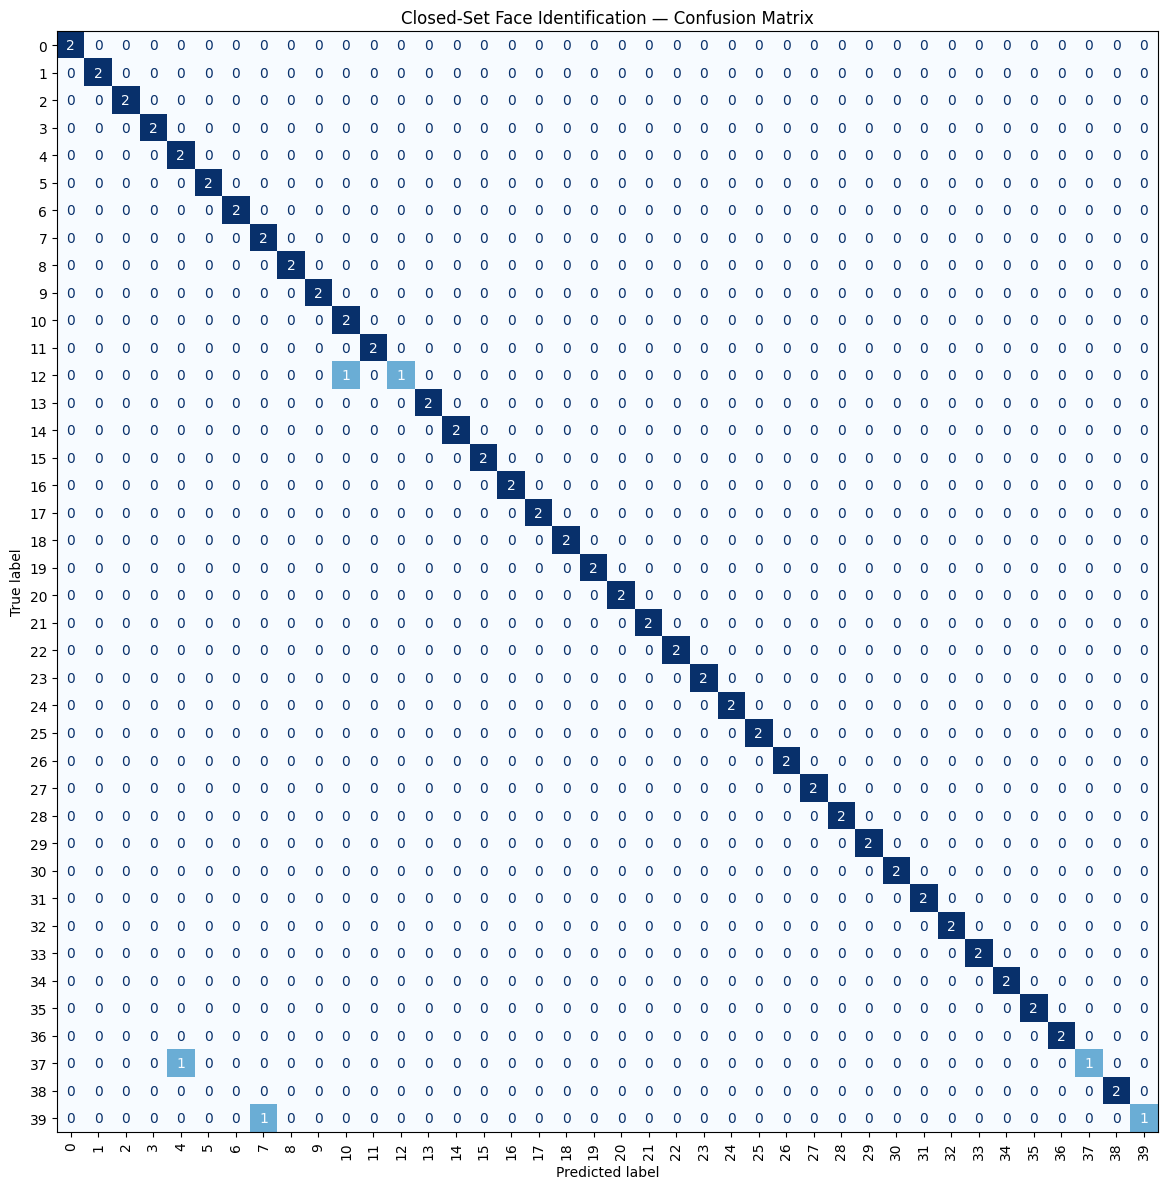

In [18]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES))
fig, ax = plt.subplots(figsize=(12, 12))
disp = ConfusionMatrixDisplay(cm, display_labels=np.arange(N_CLASSES))
disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90)
plt.title("Closed-Set Face Identification — Confusion Matrix")
plt.tight_layout()
plt.show()


### 7.2 Class-wise precision, recall, and F1-score


In [19]:
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred,
    labels=np.arange(N_CLASSES),
    zero_division=0
)

print("Macro precision:", precision.mean())
print("Macro recall   :", recall.mean())
print("Macro F1       :", f1.mean())

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(N_CLASSES),
    zero_division=0,
    digits=3
))


Macro precision: 0.975
Macro recall   : 0.9625
Macro F1       : 0.9600000000000002

Classification report:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000         2
           1      1.000     1.000     1.000         2
           2      1.000     1.000     1.000         2
           3      1.000     1.000     1.000         2
           4      0.667     1.000     0.800         2
           5      1.000     1.000     1.000         2
           6      1.000     1.000     1.000         2
           7      0.667     1.000     0.800         2
           8      1.000     1.000     1.000         2
           9      1.000     1.000     1.000         2
          10      0.667     1.000     0.800         2
          11      1.000     1.000     1.000         2
          12      1.000     0.500     0.667         2
          13      1.000     1.000     1.000         2
          14      1.000     1.000     1.000         2
          15      1.000     

### 7.3 Misclassification analysis


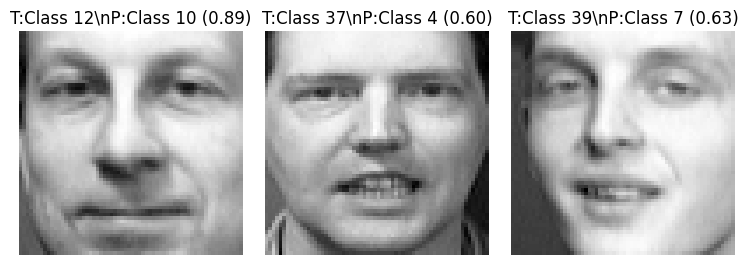

In [20]:
show_misclassified(
    test_images, y_true, y_pred, confidences,
    class_names=[f"Class {i}" for i in range(N_CLASSES)],
    n=8
)


For at least five incorrect predictions (if available), discuss plausible causes:
- pose,
- illumination,
- expression,
- blur,
- visual similarity,
- limited number of training examples.

Do not claim a causal explanation unless it is visually supported.


# 8. Fresh-image inference

For the public ORL workflow, a convenient reproducible "fresh-image" demonstration is to use an image not seen during training.  
For a custom consent-based dataset, replace this input with an uploaded image of an **enrolled consenting participant** and apply the same deterministic preprocessing.


### 8.1 Probability helper — student-completion function


In [25]:
def predict_probabilities(model, x, device):
    """
    x: tensor with shape [1,C,H,W]
    Returns predicted class, confidence, and 1-D probability vector.
    """
    model.eval()
    with torch.no_grad():
        logits = model(x.to(device))

        # YOUR CODE STARTS HERE
        # TODO: convert logits to Softmax probabilities, obtain maximum
        # probability and corresponding class index.
        probs = torch.softmax(logits, dim=1)
        pred = probs.argmax(dim=1)
        confidence = probs.max(dim=1)[0]
        # YOUR CODE ENDS HERE

    return int(pred.item()), float(confidence.item()), probs.squeeze(0).cpu().numpy()

In [26]:
test_predict_probabilities(predict_probabilities)


✓ predict_probabilities: passed


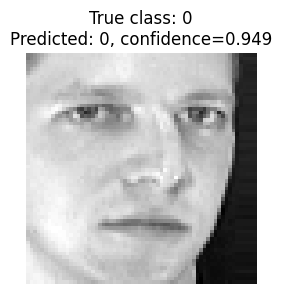

Top-5 predicted classes and probabilities:
Class 00: 0.9487
Class 07: 0.0465
Class 16: 0.0034
Class 15: 0.0006
Class 06: 0.0003


In [27]:
# Use one held-out test image as the reproducible fresh-image demonstration.
fresh_x, fresh_y = test_ds[0]
pred, conf, probs = predict_probabilities(
    face_model, fresh_x.unsqueeze(0), device
)

plt.figure(figsize=(3,3))
plt.imshow(fresh_x.squeeze().numpy(), cmap="gray")
plt.title(f"True class: {fresh_y}\nPredicted: {pred}, confidence={conf:.3f}")
plt.axis("off")
plt.show()

top5 = np.argsort(probs)[::-1][:5]
print("Top-5 predicted classes and probabilities:")
for k in top5:
    print(f"Class {k:02d}: {probs[k]:.4f}")


# 9. Closed-set limitation experiment

A standard softmax classifier always distributes probability mass across its **known classes**.

Therefore, an image from an unknown person can still receive:
- a predicted known identity,
- sometimes even a high softmax confidence.

This does **not** establish biometric identity.

### Optional demonstration
If permitted by the instructor, supply a non-enrolled face solely to observe the output distribution. Do not interpret the predicted label as that person's identity.


### Discussion questions
1. Why does Softmax necessarily assign probability mass to known classes?
2. Can a confidence threshold reject some uncertain inputs? Why is this not sufficient for robust open-set recognition?
3. Why are embedding-based methods more suitable when unknown identities must be rejected?
4. What additional validation, calibration, privacy safeguards, and operational controls would be required before any real-world use?


# 10. Optional extension — consent-based class-folder dataset

For a custom dataset, create a separate, consented collection and split physical files into mutually exclusive train/validation/test subsets.

A typical deterministic evaluation transform is:

```python
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=1),  # if using grayscale model
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])
```

If you use RGB instead:
- set \(C_{\mathrm{in}}=3\),
- change `in_channels=3`,
- use 3-channel normalization.

Keep all other stages unchanged.


# 11. Final Part-II Public Check


In [28]:
run_all_tests(globals())


✓ FaceCNN: passed
✓ stratified_indices: passed
✓ predict_probabilities: passed
All Lab-07 Part-II public tests passed.


## Part-II submission checklist
- Dataset inspected and class counts recorded.
- Mutually exclusive train/validation/test split verified.
- Training-only augmentation used.
- CNN dimensions calculated using \(H,W,C,F,P,S,K\).
- Public architecture test passed.
- Learning curves plotted and interpreted.
- Test accuracy reported.
- Confusion matrix generated.
- Class-wise precision, recall, and F1 reported.
- Misclassifications analyzed.
- Fresh-image prediction performed.
- Closed-set limitation discussed.
- Final public tests passed.
